# Holiday Retail Planner 2026 - analysis notebook

UCLA Anderson · Time Series Analysis and Forecasting · Group project (Charlotte Zhu, Shihan Wang, Jing Chang, Rachel Liu)

**Question.** How much will Americans spend in the 2026 holiday season, by retail category - and which forecaster
should a retailer trust: last year's numbers, classical time-series models, machine learning, or an AI chatbot?

This notebook walks through the full analysis. The heavy lifting lives in `src/` so the dashboard and this notebook
use exactly the same code. Set `RERUN = True` to refit every model (≈2 minutes); otherwise the saved outputs are read.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import CATEGORIES, OUTPUTS
from src.data import load_panel, quality_report
from src import evaluate

RERUN = False
pd.set_option('display.width', 160)
BLUE, ORANGE, INK, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'axes.edgecolor': GRID, 'figure.dpi': 110, 'lines.linewidth': 2})
panel = load_panel()
quality_report(panel)

,series,first,last,months,missing_inside_range,duplicates,min,max
0,total,1992-01-01,2026-09-01,417,0,0,126717.0,694088.0
1,clothing,1992-01-01,2026-08-01,416,0,0,2532.0,39105.0
2,electronics,1992-01-01,2026-08-01,416,0,0,2817.0,15243.0
3,hobby,1992-01-01,2026-08-01,416,0,0,2534.0,11888.0
4,general,1992-01-01,2026-08-01,416,0,0,14892.0,96014.0
5,ecommerce,1992-01-01,2026-08-01,416,0,0,2245.0,139317.0
6,grocery,1992-01-01,2026-08-01,416,0,0,27551.0,90541.0


## 1. Data

U.S. Census Bureau *Monthly Retail Trade*, **not seasonally adjusted** (the holiday spike is what we forecast), $ millions,
via FRED; plus the University of Michigan Consumer Sentiment index. No missing months or duplicates. The only anomaly is
the COVID lockdown (spring 2020), which models treat as an outlier.

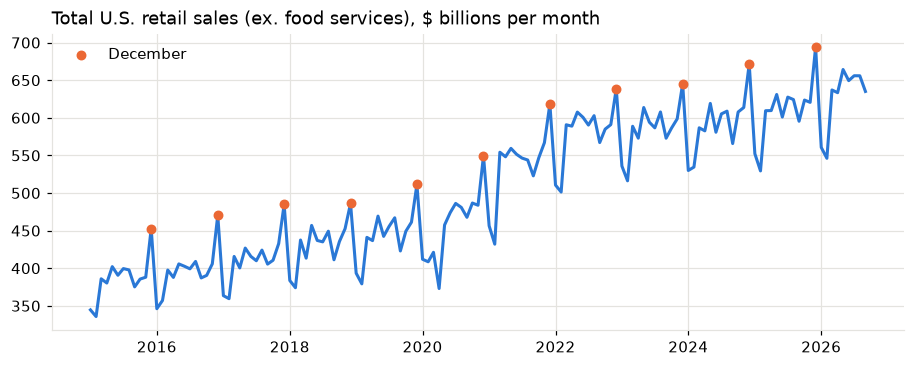

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.5))
s = panel['total'].loc['2015':]
ax.plot(s.index, s / 1000, color=BLUE)
dec = s[s.index.month == 12]
ax.scatter(dec.index, dec / 1000, color=ORANGE, zorder=3, s=30, label='December')
ax.set_title('Total U.S. retail sales (ex. food services), $ billions per month', loc='left')
ax.legend(frameon=False); plt.show()

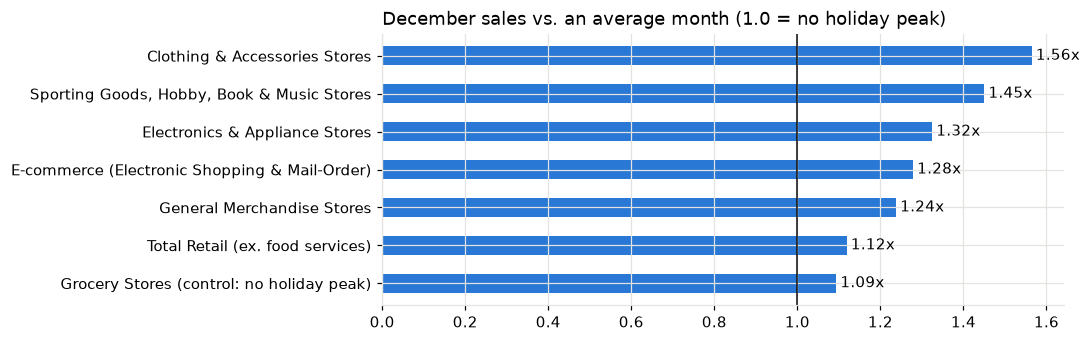

In [3]:
# How big is December relative to an average month (2022-2025)?
prof = {}
for c in CATEGORIES:
    s = panel[c].loc['2022':'2025']
    prof[c] = (s.groupby(s.index.month).sum() / s.sum() * 12)
prof = pd.DataFrame(prof)
dec = prof.loc[12].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh([CATEGORIES[c]['label'] for c in dec.index], dec.values, color=BLUE, height=0.5)
ax.axvline(1, color=INK, lw=1)
for i, v in enumerate(dec.values): ax.text(v + 0.01, i, f'{v:.2f}x', va='center')
ax.set_title('December sales vs. an average month (1.0 = no holiday peak)', loc='left'); plt.show()

In [4]:
# E-commerce share of retail, same months (Jan-Aug) each year so the comparison is fair
share = pd.Series({y: panel.loc[f'{y}-01':f'{y}-08','ecommerce'].sum() / panel.loc[f'{y}-01':f'{y}-08','total'].sum()
                   for y in range(2015, 2027)})
(share * 100).round(2).to_frame('e-commerce share, Jan-Aug (%)').T

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"e-commerce share, Jan-Aug (%)",8.31,9.1,9.88,10.55,11.34,14.83,14.69,14.74,15.94,16.48,16.86,17.43


## 2. Models and backtest design

| Model | Idea |
|---|---|
| Seasonal Naive | this December = last December (baseline: the retailer's habit) |
| Naive + Growth | last year × recent year-over-year growth |
| ETS | damped-trend exponential smoothing with monthly seasonality, log sales |
| SARIMA | seasonal ARIMA, order picked by AIC on training data only |
| SARIMAX + Sentiment | SARIMA + consumer sentiment lagged 4 months (known at forecast time) |
| XGBoost | one pooled model across categories, predicts YoY growth |
| Ensemble | average of SARIMA, ETS, XGBoost (log space) |
| Claude / GPT | LLMs forecasting from the same history in a prompt |

**Rolling origin:** for each year 2015-2025 every model is fit on data through **August** and forecasts **Sep-Dec**.
Same origin, horizon and information for all models. Main metric: absolute % error of the **Nov+Dec total**.

In [5]:
if RERUN:
    from src import backtest; backtest.main()
bt = evaluate.load_backtest()
po = evaluate.per_origin(bt, panel)
s_all = evaluate.summary(po); s_ex = evaluate.summary(po, exclude_covid=True)
fmt = {'holiday_APE': '{:.2%}', 'MAPE': '{:.2%}', 'MASE': '{:.2f}', 'Coverage80': '{:.0%}', 'win_rate_vs_naive': '{:.0%}'}
s_all.style.format(fmt, na_rep='-').set_caption('All 11 seasons (2015-2025)')

,holiday_APE,MAPE,MASE,Coverage80,n,win_rate_vs_naive
model,,,,,,
Ensemble,2.29%,2.40%,0.73,-,77,77%
SARIMA,2.34%,2.42%,0.73,83%,77,75%
SARIMAX + Sentiment,2.36%,2.43%,0.73,82%,77,71%
Naive + Growth,2.55%,2.74%,0.80,-,77,68%
ETS,2.70%,2.54%,0.76,82%,77,69%
XGBoost,2.75%,2.88%,0.87,-,77,71%
Seasonal Naive,5.32%,5.44%,1.61,-,77,-


In [6]:
s_ex.style.format(fmt, na_rep='-').set_caption('Excluding COVID seasons 2020-2021')

,holiday_APE,MAPE,MASE,Coverage80,n,win_rate_vs_naive
model,,,,,,
Ensemble,2.15%,2.13%,0.65,-,63,73%
Naive + Growth,2.19%,2.31%,0.70,-,63,63%
SARIMA,2.23%,2.19%,0.67,87%,63,71%
SARIMAX + Sentiment,2.26%,2.21%,0.67,85%,63,67%
XGBoost,2.28%,2.43%,0.73,-,63,67%
ETS,2.51%,2.30%,0.70,85%,63,65%
Seasonal Naive,3.78%,3.97%,1.19,-,63,-


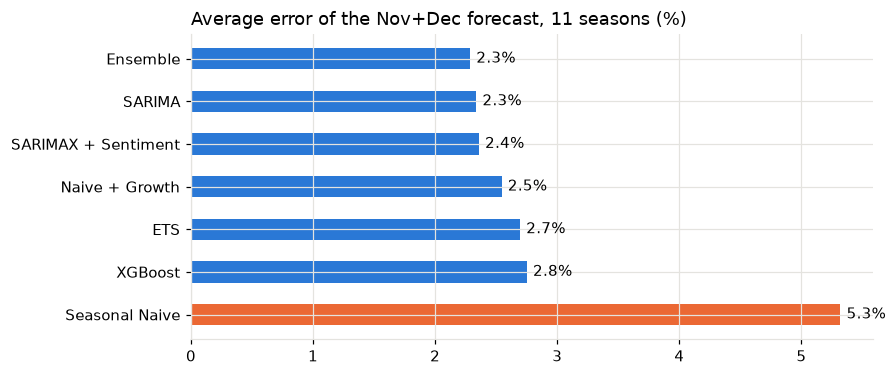

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = s_all['holiday_APE'].sort_values(ascending=False)
ax.barh(d.index, d.values * 100, color=[ORANGE if m == 'Seasonal Naive' else BLUE for m in d.index], height=0.5)
for i, v in enumerate(d.values): ax.text(v * 100 + 0.05, i, f'{v:.1%}', va='center')
ax.set_title('Average error of the Nov+Dec forecast, 11 seasons (%)', loc='left'); plt.show()

In [8]:
# By category: which are hardest to forecast?
(po.pivot_table(index='category', columns='model', values='holiday_ape') * 100).round(2)

model,ETS,Ensemble,Naive + Growth,SARIMA,SARIMAX + Sentiment,Seasonal Naive,XGBoost
category,,,,,,,
clothing,1.28,1.07,2.72,0.92,1.44,4.92,2.06
ecommerce,3.90,2.69,2.21,3.26,3.07,9.62,3.56
electronics,4.71,4.25,4.75,4.43,4.16,6.23,4.36
general,1.72,1.88,2.05,2.07,2.07,3.41,1.97
grocery,1.30,1.16,1.29,1.11,1.11,3.61,1.81
hobby,4.39,3.48,3.03,3.04,3.11,5.35,3.95
total,1.57,1.48,1.78,1.53,1.56,4.10,1.56


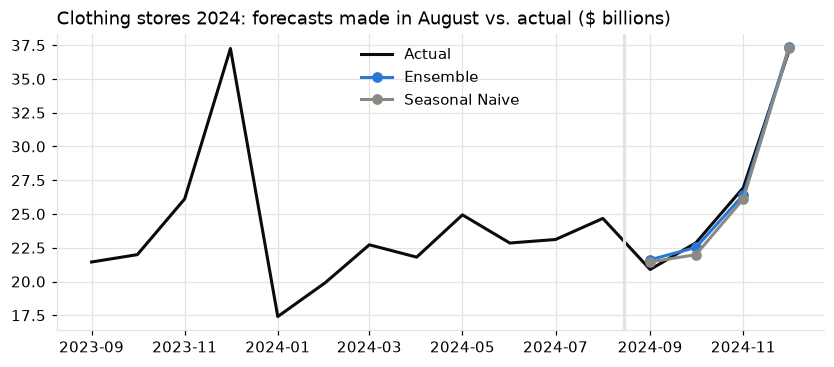

In [9]:
# Replay one season: clothing stores, 2024
cat, yr = 'clothing', 2024
fig, ax = plt.subplots(figsize=(9, 3.5))
h = panel[cat].loc[f'{yr-1}-09':f'{yr}-12']
ax.plot(h.index, h / 1000, color=INK, label='Actual')
for m, col in [('Ensemble', BLUE), ('Seasonal Naive', '#8a8984')]:
    d = bt[(bt.category == cat) & (bt.year == yr) & (bt.model == m)]
    ax.plot(d.date, d['mean'] / 1000, marker='o', color=col, label=m)
ax.axvline(pd.Timestamp(f'{yr}-08-15'), color=GRID)
ax.set_title(f'Clothing stores {yr}: forecasts made in August vs. actual ($ billions)', loc='left')
ax.legend(frameon=False); plt.show()

**Are the intervals honest?** A good 80% interval should contain the actual value about 80% of the time.
SARIMA's and ETS's coverage is in the table above (`Coverage80`) - close to 80%, so we use the forecast-error spread
for the planner's scenarios.

## 3. Can AI chatbots forecast?

LLMs may have *memorized* the published Census numbers. So the main test hides everything that could be looked up:
the series becomes an index (first month = 100) labelled only by calendar month - no category, no year. For Claude we also
ran **named** prompts (real dates, category and dollars). If named prompts are much better on past seasons, that gap is
evidence of recall rather than skill.

In [10]:
from src.llm_forecast import build_prompt
print(build_prompt(panel['clothing'].dropna(), pd.Timestamp('2024-08-01'), 'clothing', 'anonymized')[0][-420:])

n: 90.4
Feb: 101.4
Mar: 127.7
Apr: 128.3
May: 133.0
Jun: 123.7
Jul: 124.8
Aug: 130.0
Sep: 117.4
Oct: 123.0
Nov: 141.9
Dec: 198.6
Jan: 96.5
Feb: 104.0
Mar: 123.6
Apr: 122.5
May: 131.4
Jun: 122.8
Jul: 125.7
Aug: 134.3
Sep: 117.6
Oct: 120.5
Nov: 143.2
Dec: 204.2
Jan: 95.4
Feb: 109.1
Mar: 124.5
Apr: 119.5
May: 136.7
Jun: 125.3
Jul: 126.7
Aug: 135.2

Forecast the next 4 months (Sep, Oct, Nov, Dec) on the same index scale.


In [11]:
llm = [m for m in s_all.index if m.startswith(('Claude', 'GPT'))]
if llm:
    display(s_all.loc[llm + ['Ensemble', 'Seasonal Naive']].style.format(fmt, na_rep='-'))
    mm = po[po.model.isin(['Claude (anonymized)', 'Claude (named)'])].pivot_table(index='year', columns='model', values='holiday_ape')
    display((mm * 100).round(2))
else:
    print('LLM results not generated yet - run python -m src.llm_forecast with API keys in .env')

LLM results not generated yet - run python -m src.llm_forecast with API keys in .env


## 4. The 2026 forecast

In [12]:
f26 = pd.read_csv(OUTPUTS / 'forecast_2026.csv', parse_dates=['date', 'origin'])
llm26 = OUTPUTS / 'llm_forecast_2026.csv'
if llm26.exists():
    f26 = pd.concat([f26, pd.read_csv(llm26, parse_dates=['date', 'origin'])])
hol = f26[f26.date.dt.month >= 11].groupby(['category', 'model'])['mean'].sum().unstack()
ly = panel.loc['2025-11':'2025-12'].sum()
growth = hol.div(ly[hol.index], axis=0) - 1
(growth * 100).round(1)

model,ETS,Ensemble,Naive + Growth,SARIMA,SARIMAX + Sentiment,Seasonal Naive,XGBoost
category,,,,,,,
clothing,0.3,2.9,4.3,4.2,4.6,0.0,4.2
ecommerce,8.8,9.6,8.9,10.7,10.4,0.0,9.3
electronics,4.8,5.8,7.2,6.4,6.6,0.0,6.3
general,3.3,3.7,3.4,4.0,4.0,0.0,3.9
grocery,0.3,1.1,0.5,1.4,1.5,0.0,1.5
hobby,4.9,7.7,10.8,8.3,8.3,0.0,9.9
total,4.5,5.2,5.9,5.5,5.5,0.0,5.6


In [13]:
# Early reality check: September 2026 total retail was published after our August origin
f26[(f26.category == 'total') & (f26.date == '2026-09-01')][['model', 'mean', 'actual']].assign(
    error=lambda d: (d['mean'] / d['actual'] - 1).map('{:+.1%}'.format))

,model,mean,actual,error
0,Seasonal Naive,595443.000000,635056.0,-6.2%
4,Naive + Growth,630408.363929,635056.0,-0.7%
8,ETS,619903.891428,635056.0,-2.4%
12,SARIMA,622676.778078,635056.0,-1.9%
16,SARIMAX + Sentiment,622542.452905,635056.0,-2.0%
140,XGBoost,630023.894811,635056.0,-0.8%
192,Ensemble,624186.949882,635056.0,-1.7%


## 5. From forecast to order (the planner's math)

Example: a clothing boutique sold 5,000 units last Nov+Dec, has 1,200 on hand, wants a 90% chance of not running out,
and estimates its own sales typically miss plan by ±10%.

In [14]:
from scipy.stats import norm
g = growth.loc['clothing', 'Ensemble']
pe = po[(po.model == 'Ensemble') & (po.category == 'clothing') & (~po.year.isin([2020, 2021]))]['holiday_pe']
sigma_nat = np.sqrt((pe ** 2).mean()); sigma = np.sqrt(sigma_nat ** 2 + 0.10 ** 2)
expected = 5000 * (1 + g); safety = norm.ppf(0.90) * sigma * expected
order = max(0, expected + safety - 1200)
print(f'growth {g:+.1%} | national error {sigma_nat:.1%} | total sigma {sigma:.1%}')
print(f'expected {expected:,.0f} + safety {safety:,.0f} - on hand 1,200 = order {np.ceil(order):,.0f} units')

growth +2.9% | national error 1.2% | total sigma 10.1%
expected 5,144 + safety 664 - on hand 1,200 = order 4,609 units


## 6. Conclusions

1. **Forecasting beats habit:** every model roughly halves the error of "same as last year"; the ensemble is best.
2. **Consumer sentiment does not help:** adding it to SARIMA does not reduce error - shoppers' mood and spending diverge.
3. **LLMs:** see section 3 for how close they come once memorization is ruled out.
4. **2026:** solid growth overall, led by e-commerce, which keeps taking share.
5. **Limits:** national data (not a store), revised data (not real-time vintages), 11 seasons is a small sample, and no
   inventory-cost data, so no claims about money saved.